In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:
# Load Dataset
df = pd.read_csv("HousingData.csv")

# Display first 5 rows
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


In [3]:
print(df.shape)

print(df.info())

print(df.describe())

print(df.isnull().sum())

(506, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      486 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    486 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB
None
             CRIM          ZN       INDUS        CHAS         NOX          RM  \
count  486.000000  486.000000  486.000000  486.000000  506.000000  506.000000   
mean     3.611874   11.211934   11.083992    0.069959    0

In [4]:
imputer = SimpleImputer(strategy="mean")

df = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

In [5]:
X = df.drop("MEDV", axis=1)
y = df["MEDV"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [7]:
model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [8]:
y_pred = model.predict(X_test)

In [9]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE : 3.1499233573457692
MSE : 25.01767202384268
RMSE: 5.0017668901941725
R2 Score: 0.6588520195508143


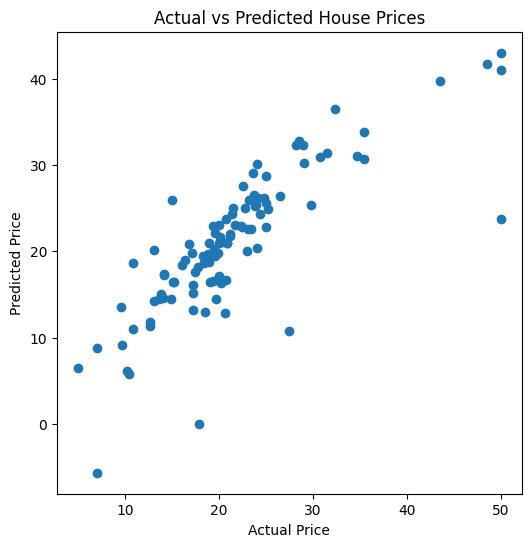

In [10]:
plt.figure(figsize=(6,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [11]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

importance.sort_values(by="Coefficient", ascending=False)

,Feature,Coefficient
5,RM,4.752410
3,CHAS,3.240673
8,RAD,0.222823
1,ZN,0.029016
11,B,0.012263
9,TAX,-0.009151
6,AGE,-0.019520
2,INDUS,-0.027133
0,CRIM,-0.114140
12,LSTAT,-0.438440


In [12]:
plt.figure(figsize=(10,8))
df.corr().round(2)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
CRIM,1.00,-0.18,0.39,-0.05,0.41,-0.22,0.34,-0.37,0.61,0.57,0.27,-0.37,0.43,-0.38
ZN,-0.18,1.00,-0.51,-0.04,-0.50,0.32,-0.54,0.64,-0.31,-0.31,-0.40,0.17,-0.41,0.37
INDUS,0.39,-0.51,1.00,0.06,0.74,-0.38,0.61,-0.70,0.59,0.72,0.38,-0.35,0.57,-0.48
CHAS,-0.05,-0.04,0.06,1.00,0.07,0.10,0.08,-0.09,0.00,-0.03,-0.11,0.05,-0.05,0.18
NOX,0.41,-0.50,0.74,0.07,1.00,-0.30,0.71,-0.77,0.61,0.67,0.19,-0.38,0.57,-0.43
RM,-0.22,0.32,-0.38,0.10,-0.30,1.00,-0.24,0.21,-0.21,-0.29,-0.36,0.13,-0.60,0.70
AGE,0.34,-0.54,0.61,0.08,0.71,-0.24,1.00,-0.72,0.45,0.50,0.26,-0.27,0.57,-0.38
DIS,-0.37,0.64,-0.70,-0.09,-0.77,0.21,-0.72,1.00,-0.49,-0.53,-0.23,0.29,-0.48,0.25
RAD,0.61,-0.31,0.59,0.00,0.61,-0.21,0.45,-0.49,1.00,0.91,0.46,-0.44,0.47,-0.38
TAX,0.57,-0.31,0.72,-0.03,0.67,-0.29,0.50,-0.53,0.91,1.00,0.46,-0.44,0.52,-0.47


<Figure size 1000x800 with 0 Axes>

In [13]:
print(df.corr())

             CRIM        ZN     INDUS      CHAS       NOX        RM       AGE  \
CRIM     1.000000 -0.182930  0.391161 -0.052223  0.410377 -0.215434  0.344934   
ZN      -0.182930  1.000000 -0.513336 -0.036147 -0.502287  0.316550 -0.541274   
INDUS    0.391161 -0.513336  1.000000  0.058035  0.740965 -0.381457  0.614592   
CHAS    -0.052223 -0.036147  0.058035  1.000000  0.073286  0.102284  0.075206   
NOX      0.410377 -0.502287  0.740965  0.073286  1.000000 -0.302188  0.711461   
RM      -0.215434  0.316550 -0.381457  0.102284 -0.302188  1.000000 -0.241351   
AGE      0.344934 -0.541274  0.614592  0.075206  0.711461 -0.241351  1.000000   
DIS     -0.366523  0.638388 -0.699639 -0.091680 -0.769230  0.205246 -0.724353   
RAD      0.608886 -0.306316  0.593176  0.001425  0.611441 -0.209847  0.449989   
TAX      0.566528 -0.308334  0.716062 -0.031483  0.668023 -0.292048  0.500589   
PTRATIO  0.273384 -0.403085  0.384806 -0.109310  0.188933 -0.355501  0.262723   
B       -0.370163  0.167431 